# Systemy AI – Laboratorium 6
## Zadanie: klasyfikator recenzji IMDB na pełnym zbiorze

Zbuduj klasyfikator nastroju recenzji (pozytywna / negatywna) na **pełnym** zbiorze IMDB: 25 000 recenzji treningowych i 25 000 testowych. Wzoruj się na notatniku `SystemyAI_Lab6_IMDB_wzor.ipynb`; cały kod piszesz sam(a).

**Czas obliczeń.** Zbiór jest 5 razy większy niż we wzorze. Pojedyncza walidacja krzyżowa trwa kilkanaście–kilkadziesiąt sekund, strojenie w punkcie 4 – kilka minut. Dlatego używamy **3 rund** walidacji krzyżowej zamiast 5.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie i czyszczenie
1. Wczytaj zbiór `stanfordnlp/imdb` z Hugging Face do `train_df` i `test_df` (kolumny `text`, `label`). Skopiuj z wzoru wersję z zapasowym wczytaniem z GitHuba.
2. Zamień `<br />` na spacje w obu zbiorach.
3. Policz `class_share` (udział klas w `train_df`) i `median_words` (mediana liczby słów w recenzji treningowej).

In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

try:
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    train_df = imdb["train"].to_pandas()
    test_df = imdb["test"].to_pandas()
except Exception as e:
    print("Hugging Face niedostępny – wczytuję kopię z GitHuba.", type(e).__name__)
    URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
    df = pd.read_csv(URL).rename(columns={"review": "text"})
    df["label"] = (df["sentiment"] == "positive").astype(int)
    train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.5,
                                         stratify=df["label"], random_state=0)

train_df["text"] = train_df["text"].str.replace("<br />", " ", regex=False)
test_df["text"] = test_df["text"].str.replace("<br />", " ", regex=False)

class_share = train_df["label"].value_counts(normalize=True)
median_words = train_df["text"].str.split().str.len().median()

print(train_df.shape, test_df.shape)
print(class_share.round(3))
print("mediana słów:", median_words)

(25000, 2) (25000, 2)
label
0    0.5
1    0.5
Name: proportion, dtype: float64
mediana słów: 173.0


In [12]:
# TEST
assert train_df.shape == (25000, 2) and test_df.shape == (25000, 2)
assert abs(class_share[1] - 0.5) < 0.01
assert not train_df["text"].str.contains("<br />").any()
assert 150 < median_words < 200
print("1 OK")

1 OK


---
## 2. Porównanie trzech klasyfikatorów
1. Utwórz `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
2. Dla pipeline'ów `TfidfVectorizer()` + klasyfikator: `MultinomialNB()`, `LinearSVC()`, `LogisticRegression(max_iter=1000)` policz `cross_validate` na **całym** zbiorze treningowym.
3. Wyniki zbierz w tabeli `porownanie` (indeks: `"naiwny Bayes"`, `"liniowy SVM"`, `"regresja logistyczna"`; kolumny: `"CV"`, `"CV odch."`, `"czas uczenia [s]"`).

In [13]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

X_train, y_train = train_df["text"], train_df["label"]
X_test, y_test = test_df["text"], test_df["label"]

klasyfikatory = {
    "naiwny Bayes": MultinomialNB(),
    "liniowy SVM": LinearSVC(),
    "regresja logistyczna": LogisticRegression(max_iter=1000),
}

wiersze = []
for nazwa, klf in klasyfikatory.items():
    r = cross_validate(make_pipeline(TfidfVectorizer(), klf), X_train, y_train, cv=cv)
    wiersze.append({"model": nazwa, "CV": r["test_score"].mean(), "CV odch.": r["test_score"].std(),
                    "czas uczenia [s]": r["fit_time"].mean()})

porownanie = pd.DataFrame(wiersze).set_index("model")
porownanie.round(3)

,CV,CV odch.,czas uczenia [s]
model,,,
naiwny Bayes,0.862,0.002,3.995
liniowy SVM,0.893,0.001,3.909
regresja logistyczna,0.885,0.002,6.024


In [14]:
# TEST
assert list(porownanie.index) == ["naiwny Bayes", "liniowy SVM", "regresja logistyczna"]
assert porownanie["CV"].between(0.83, 0.92).all()
assert porownanie.loc["liniowy SVM", "CV"] > porownanie.loc["naiwny Bayes", "CV"]
print("2 OK")

2 OK


*Twoja odpowiedź:* porównaj wyniki z wynikami z wzoru (podzbiór 5000 recenzji). Co dało pięciokrotne zwiększenie zbioru treningowego? Czy kolejność modeli się zmieniła?

Odpowiedź:
Na pełnym zbiorze wszystkie modele są lepsze niż we wzorze: naiwny Bayes 0.820 -> 0.862, liniowy SVM 0.862 -> 0.893, regresja logistyczna 0.841 -> 0.885, czyli zysk ok. 3-4 p.p. Odchylenie w CV też spadło (z ok. 0.010 do 0.001-0.002), bo części walidacyjne są dużo większe. Kolejność modeli się nie zmieniła: najlepszy jest liniowy SVM, potem regresja logistyczna, na końcu naiwny Bayes.

---
## 3. Strojenie: `GridSearchCV`
Dostrój pipeline `TfidfVectorizer(min_df=2)` + `LinearSVC()`:
- `tfidfvectorizer__ngram_range` ∈ {(1, 1), (1, 2)},
- `linearsvc__C` ∈ {0.1, 1}.

Obiekt zapisz w `gs` (z `cv=cv`), wypisz `best_params_` i `best_score_`. **To potrwa kilka minut** – w tym czasie odpowiedz na pytanie pod komórką.

In [15]:
siatka = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "linearsvc__C": [0.1, 1],
}

gs = GridSearchCV(make_pipeline(TfidfVectorizer(min_df=2), LinearSVC()), siatka, cv=cv)
gs.fit(X_train, y_train)

print("najlepsze:", gs.best_params_)
print(f"CV = {gs.best_score_:.3f}")

pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "mean_fit_time"]].round(3)

najlepsze: {'linearsvc__C': 1, 'tfidfvectorizer__ngram_range': (1, 2)}
CV = 0.906


,params,mean_test_score,mean_fit_time
0,"{'linearsvc__C': 0.1, 'tfidfvectorizer__ngram_...",0.888,3.893
1,"{'linearsvc__C': 0.1, 'tfidfvectorizer__ngram_...",0.889,11.267
2,"{'linearsvc__C': 1, 'tfidfvectorizer__ngram_ra...",0.892,3.810
3,"{'linearsvc__C': 1, 'tfidfvectorizer__ngram_ra...",0.906,12.160


In [16]:
# TEST
assert gs.best_params_["tfidfvectorizer__ngram_range"] == (1, 2), "Na pełnym zbiorze bigramy powinny pomagać"
assert gs.best_score_ > porownanie.loc["liniowy SVM", "CV"]
print("3 OK")

3 OK


*Twoja odpowiedź:* we wzorze bigramy na 5000 recenzjach nic nie dały. Czy na pełnym zbiorze jest inaczej? Dlaczego większy zbiór pomaga właśnie bigramom? Ile razy wolniej uczy się model z bigramami i dlaczego?

Odpowiedź:
Na pełnym zbiorze bigramy pomagają: dla C = 1 wynik rośnie z 0.892 do 0.906. Każda para słów występuje dużo rzadziej niż pojedyncze słowo, więc model potrzebuje więcej danych, żeby nauczyć się jej wagi. Z bigramami uczenie trwa ok. 3 razy dłużej (12.2 s zamiast 3.8 s), bo słownik jest dużo większy (436 tys. cech).

---
## 4. Ocena końcowa
`model_koncowy = gs.best_estimator_`. Policz `acc_test` (accuracy na **całym** zbiorze testowym – jedyny raz, kiedy go używasz), narysuj macierz pomyłek i wypisz `classification_report`.

accuracy (test): 0.903


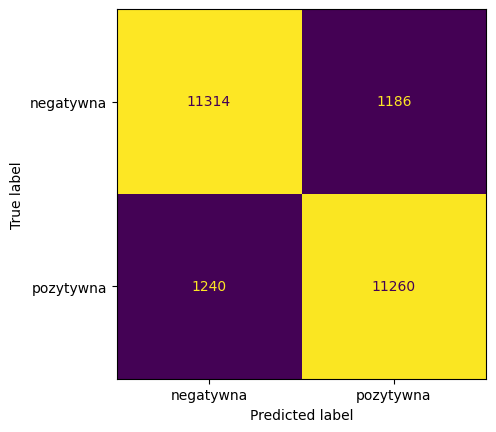

              precision    recall  f1-score   support

   negatywna      0.901     0.905     0.903     12500
   pozytywna      0.905     0.901     0.903     12500

    accuracy                          0.903     25000
   macro avg      0.903     0.903     0.903     25000
weighted avg      0.903     0.903     0.903     25000



In [17]:
model_koncowy = gs.best_estimator_

y_pred = model_koncowy.predict(X_test)
acc_test = (y_pred == y_test.values).mean()
print(f"accuracy (test): {acc_test:.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["negatywna", "pozytywna"], colorbar=False)
plt.show()

print(classification_report(y_test, y_pred, target_names=["negatywna", "pozytywna"], digits=3))

In [18]:
# TEST
assert 0.87 < acc_test < 0.93
print("4 OK")

4 OK


---
## 5. Co model „wie” i gdzie się myli
1. Z `model_koncowy` wyciągnij nazwy cech (`model_koncowy[0].get_feature_names_out()`) i wagi (`model_koncowy[-1].coef_[0]`) do `pd.Series` o nazwie `wagi`. Wypisz po 15 cech o największej i najmniejszej wadze. Czy są wśród nich bigramy?
2. `bledy` – `DataFrame` z recenzjami testowymi, które model sklasyfikował źle (kolumny `text`, `label`, `pred`). Wypisz liczbę błędów i przeczytaj **3 przykłady** (pierwsze 500 znaków).
3. Napisz **5 własnych recenzji** (po angielsku), w tym co najmniej jedną z negacją i jedną ironiczną, i sprawdź predykcje modelu.

In [19]:
slowa = model_koncowy[0].get_feature_names_out()
wagi = pd.Series(model_koncowy[-1].coef_[0], index=slowa).sort_values()
print("liczba cech:", len(wagi))

print("\nnajbardziej negatywne:")
print(wagi.head(15).round(2))
print("\nnajbardziej pozytywne:")
print(wagi.tail(15).round(2))

bledy = test_df.copy()
bledy["pred"] = y_pred
bledy = bledy[bledy["label"] != bledy["pred"]]
print("\nliczba błędów:", len(bledy))

for _, w in bledy.head(3).iterrows():
    print(f"\n--- prawda: {w['label']}, model: {w['pred']} ---")
    print(w["text"][:500])

moje = [
    "One of the best films I have seen this year, great acting and a beautiful story.",
    "Terrible script and the actors looked bored the whole time.",
    "The movie was not bad at all, I actually enjoyed it.",
    "Oh great, another two hours of my life I will never get back. Brilliant.",
    "I wanted to love this film, but in the end it was just a waste of time.",
]
for tekst, pred, wynik in zip(moje, model_koncowy.predict(moje), model_koncowy.decision_function(moje)):
    print(f"{pred}  ({wynik:+.2f})  {tekst}")

liczba cech: 436597

najbardziej negatywne:
worst            -4.19
awful            -3.72
bad              -3.64
boring           -3.46
poor             -3.27
the worst        -3.18
waste            -2.92
disappointment   -2.60
terrible         -2.58
worse            -2.57
poorly           -2.51
disappointing    -2.46
dull             -2.42
unfortunately    -2.40
annoying         -2.33
dtype: float64

najbardziej pozytywne:
best         1.84
favorite     1.85
bit          1.86
loved        1.88
superb       1.91
brilliant    1.95
the best     1.96
enjoyable    1.96
today        2.20
amazing      2.21
fun          2.29
wonderful    2.57
perfect      2.75
excellent    3.24
great        3.57
dtype: float64

liczba błędów: 2426

--- prawda: 0, model: 1 ---
First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. 

In [20]:
# TEST
assert len(wagi) > 100_000, "Słownik powinien zawierać bigramy"
assert set(bledy.columns) >= {"text", "label", "pred"} and len(bledy) == (y_pred != y_test.values).sum()
assert any(" " in w for w in wagi.head(50).index) or any(" " in w for w in wagi.tail(50).index)
print("5 OK")

5 OK


*Twoja odpowiedź:*
1. Jakie bigramy znalazły się wśród najważniejszych cech? Co mówią o tym, czego model się nauczył?
2. Opisz trzy przeczytane błędy: dlaczego model mógł się pomylić? Czy człowiek też miałby wątpliwości?
3. Które z Twoich recenzji model ocenił źle? Co mają wspólnego?
4. Gdzie leży granica podejścia „worek słów + model liniowy”? Co musiałby umieć model, żeby poradzić sobie z Twoimi trudnymi przykładami?

Odpowiedź:
1. Wśród najważniejszych cech są bigramy "the worst" (-3.18) i "the best" (+1.96). Model nauczył się, że całe zwroty typu "the worst" mocniej wskazują opinię niż samo słowo. Są też słowa bez opinii, np. "bit" i "today" po stronie pozytywnej - to tylko korelacje z danymi, nie znaczenie słów.
2. Wszystkie trzy to negatywne recenzje uznane za pozytywne. W pierwszej autor chwali gatunek i aktora ("enjoy", "good"), a krytyka jest dopiero na końcu. Druga to prawie samo streszczenie fabuły, bez opinii. W trzeciej pozytywne słowa dotyczą innych filmów. Przy pierwszych dwóch człowiek też mógłby mieć problem.
3. Źle oceniona została recenzja ironiczna ("Oh great, another two hours of my life I will never get back. Brilliant.") - model uznał ją za pozytywną (+0.33) przez słowa "great" i "brilliant". Recenzja z negacją ("not bad at all") wyszła dobrze, ale ledwo (+0.13). Obie mają słowa o przeciwnym wydźwięku niż cała wypowiedź.
4. Worek słów widzi tylko, jakie słowa (i pary słów) wystąpiły, a nie ich kontekst. Nie rozumie ironii, negacji na dłuższym odcinku ani porównań z innymi filmami. Żeby poradzić sobie z takimi przykładami, model musiałby rozumieć sens całego zdania i kolejność słów - to potrafią modele oparte na embeddingach i transformerach.